# Thermal context layer: quality check

**What:** for every pair, the median Landsat land surface temperature (LST) of *other* dates in the same season
(±60 days of the year, 2013–2025). Scenes within ±16 days of the pair's own Landsat date are left out, so the
target never leaks into the input.

**Why:** it is the input of the thermal branch of the fusion model: it tells the model where a place is *usually*
hot. Produced by `urbanheat thermal-context` (Earth Engine); format in `docs/CONTRACTS.md` section 1b.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio
from pathlib import Path
from urbanheat.config import load_config

cfg = load_config()                       # configs/default.yaml + your configs/local.yaml
plt.rcParams["figure.dpi"] = 90

In [2]:
root = Path(cfg["data"]["derived_dir"]) / "thermal_context"
s = pd.read_csv(root / "summary.csv")
print(f"{len(s)} pairs")
s.groupby("sensor")[["n_scenes", "median_n_obs", "coverage", "r_with_target"]].median().round(2)

422 pairs


,n_scenes,median_n_obs,coverage,r_with_target
sensor,,,,
EMIT,114.5,93.46,1.0,0.87
ENMAP,202.0,118.00,1.0,0.92
HYPERION,136.0,98.00,1.0,0.83


## How many observations, and how well does the context match the target pattern?

`r_with_target` is the pixel-by-pixel correlation between the context and the pair's own LST. High values mean
each place's hot and cool spots are stable over time.

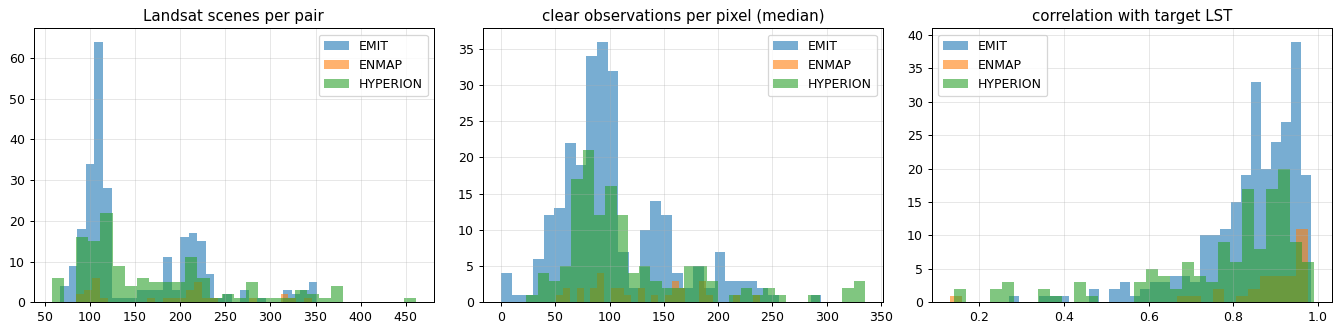

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for sensor, g in s.groupby("sensor"):
    ax[0].hist(g.n_scenes, bins=30, alpha=.6, label=sensor)
    ax[1].hist(g.median_n_obs, bins=30, alpha=.6, label=sensor)
    ax[2].hist(g.r_with_target, bins=30, alpha=.6, label=sensor)
for a, t in zip(ax, ["Landsat scenes per pair", "clear observations per pixel (median)", "correlation with target LST"]):
    a.set_title(t); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [4]:
weak = s[(s.coverage < 0.95) | (s.median_n_obs < 10)]
print(f"{len(weak)} pairs with partial coverage or few observations (their missing pixels are dropped by the valid mask):")
weak[["pair_id", "n_scenes", "median_n_obs", "coverage", "r_with_target"]].round(2)

18 pairs with partial coverage or few observations (their missing pixels are dropped by the valid mask):


,pair_id,n_scenes,median_n_obs,coverage,r_with_target
33,EMIT_150,325,121.78,0.93,0.97
72,EMIT_206,123,0.00,0.35,0.73
95,EMIT_234,76,26.00,0.90,0.55
118,EMIT_265,141,0.00,0.35,0.92
122,EMIT_272,77,33.08,0.93,0.83
131,EMIT_288,170,0.00,0.35,0.78
136,EMIT_296,182,53.66,0.59,0.94
137,EMIT_297,121,61.02,0.90,0.95
144,EMIT_304,155,74.00,0.58,0.68
200,EMIT_376,205,133.31,0.58,0.94


## Context vs target, one pair per sensor

Same colour scale in each row. The context has the same hot spots as the target; only the overall level differs
(other days were hotter or cooler), which the weather inputs and the anomaly target take care of.

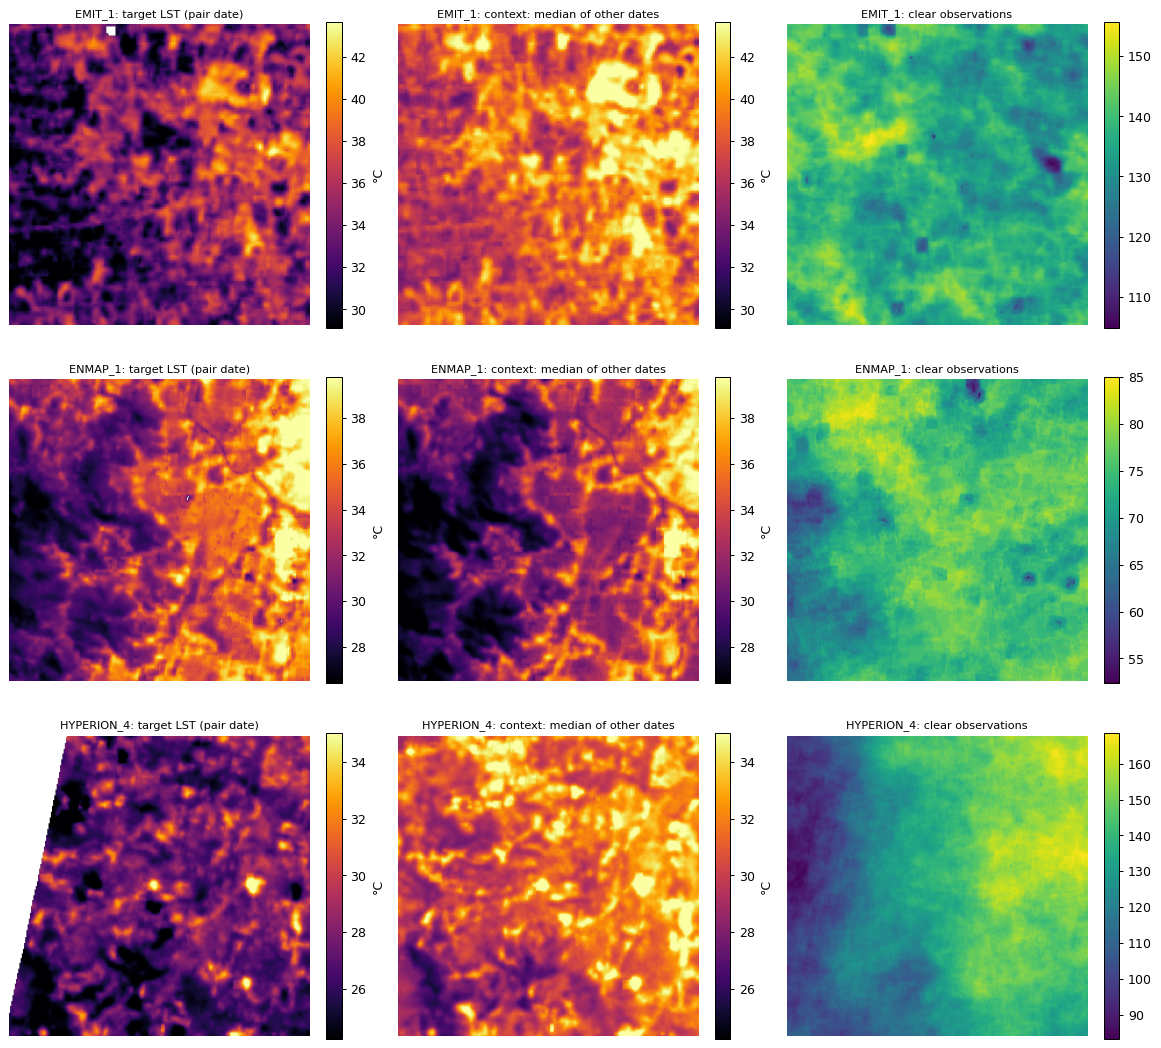

In [5]:
idx = pd.read_csv(cfg["data"]["index_file"])
idx["pair_id"] = idx.sensor + "_" + idx.pair_no.astype(str)
raw = Path(cfg["data"]["raw_dir"])
fig, ax = plt.subplots(3, 3, figsize=(13, 12))
for i, sensor in enumerate(["EMIT", "ENMAP", "HYPERION"]):
    r = idx[(idx.sensor == sensor) & idx.pair_id.isin(s[s.coverage > 0.99].pair_id)].iloc[0]
    with rasterio.open(raw / r.rel_dir / r.landsat_file) as f:
        target = f.read(list(f.descriptions).index("LST_K") + 1) - 273.15
    with rasterio.open(root / r.rel_dir / "thermal_context.tif") as f:
        ctx, n = f.read(1), f.read(2)
    lo, hi = np.nanpercentile(np.r_[target.ravel(), ctx.ravel()], [2, 98])
    for j, (a, title, kw) in enumerate([(target, "target LST (pair date)", dict(vmin=lo, vmax=hi, cmap="inferno")),
                                        (ctx, "context: median of other dates", dict(vmin=lo, vmax=hi, cmap="inferno")),
                                        (n, "clear observations", dict(cmap="viridis"))]):
        im = ax[i, j].imshow(a, **kw); ax[i, j].set_title(f"{r.pair_id}: {title}", fontsize=9); ax[i, j].axis("off")
        plt.colorbar(im, ax=ax[i, j], fraction=0.046, label="°C" if j < 2 else "")
plt.tight_layout(); plt.show()

## Summary

- Context computed for all 422 pairs, no failures; typically ~120 Landsat scenes per pair and ~100 clear
  observations per pixel.
- Median correlation with the target pattern is about 0.86: a place's hot and cool spots are stable over time,
  so the thermal branch will carry a lot of the prediction. The interesting question for the fusion model is
  what the hyperspectral data adds on top of it.
- A few pairs (mostly EMIT scenes at Landsat scene edges) have partial coverage; those pixels are excluded.